In [3]:
import pandas as pd, numpy as np, scipy.stats as st
import statsmodels.formula.api as smf, statsmodels.api as sm
import matplotlib.pyplot as plt
# import data
df = pd.read_excel("TeamStats.xlsx")
d = df.loc[:, "#Bat":"CS/G"]

### 1)

In [4]:
# calculate the number of observations
n = d.count()
# calculate the standard error of the skew and kurtosis
se_s = np.sqrt(6*n*(n-1)/((n-2)*(n+1)*(n+3)))
se_k = 2*se_s*np.sqrt((n**2-1)/((n-3)*(n+5)))
# calculate the descriptive statistics
t = pd.DataFrame({"N": n, "Min": d.min(), "Max": d.max(), "Mean": d.mean(), "SD": d.std(),
    "Skew": d.apply(lambda c: st.skew(c.dropna(), bias=False)), "SE Skew": se_s,
    "Kurt": d.apply(lambda c: st.kurtosis(c.dropna(), bias=False)), "SE Kurt": se_k})
t["Normal?"] = (t.Skew.abs() < 2*t["SE Skew"]) & (t.Kurt.abs() < 2*t["SE Kurt"])
display(t.round(3))

,N,Min,Max,Mean,SD,Skew,SE Skew,Kurt,SE Kurt,Normal?
#Bat,636,34.000,71.000,47.385,5.588,0.535,0.097,0.507,0.194,False
BatAge,636,24.800,33.500,28.707,1.359,0.354,0.097,0.226,0.194,False
R/G,636,3.170,6.040,4.566,0.505,0.274,0.097,-0.085,0.194,False
G,636,60.000,163.000,161.799,4.055,-24.998,0.097,628.563,0.194,False
1B/G,636,4.698,7.321,5.826,0.431,0.199,0.097,0.076,0.194,False
2B/G,636,1.241,2.321,1.761,0.176,0.204,0.097,0.143,0.194,False
3B/G,636,0.031,0.377,0.181,0.056,0.474,0.097,0.349,0.194,False
HR/G,636,0.562,1.895,1.074,0.224,0.327,0.097,-0.009,0.194,False
SB/G,636,0.117,1.377,0.575,0.191,0.588,0.097,0.286,0.194,False
CS/G,636,0.062,0.457,0.225,0.067,0.566,0.097,0.422,0.194,False


### 2)

In [5]:
# keep 7 variables only to match SPSS output
s = d.iloc[:, :7]
# median, range, and quartiles
q = s.apply(lambda c: pd.Series(np.percentile(c.dropna(), [25, 50, 75], method="weibull"), index=[25, 50, 75]))
t2 = pd.DataFrame({"N": s.count(), "Median": s.median(), "Range": s.max() - s.min(),
    "Q1": q.loc[25], "Q2": q.loc[50], "Q3": q.loc[75]})
display(t2.round(3))

,N,Median,Range,Q1,Q2,Q3
#Bat,636,47.000,37.000,43.000,47.000,51.000
BatAge,636,28.600,8.700,27.800,28.600,29.600
R/G,636,4.540,2.870,4.220,4.540,4.898
G,636,162.000,103.000,162.000,162.000,162.000
1B/G,636,5.818,2.623,5.525,5.818,6.117
2B/G,636,1.753,1.080,1.643,1.753,1.870
3B/G,636,0.179,0.346,0.141,0.179,0.216


### 3)

#### a)

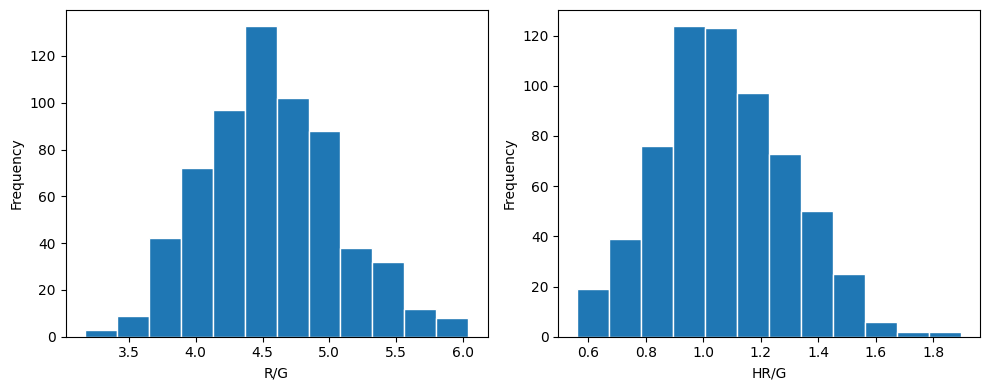

In [13]:
# histograms for R/G and one more variable, HR/G
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["R/G", "HR/G"]):
    ax.hist(df[col], bins=12, edgecolor="white")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
fig.tight_layout()
plt.show()

R/G has one main peak at 4.5 runs per game. A few teams sit out in the tails near 3.2 and 6. The shape is roughly symmetric, with a slightly longer right tail, so it looks roughly normal.

HR/G has one main peak, near 1.0 home run per game. The right tail is longer, with a few teams near 1.8. It is skewed right, so it is less symmetric than R/G but still roughly normal.

#### b)

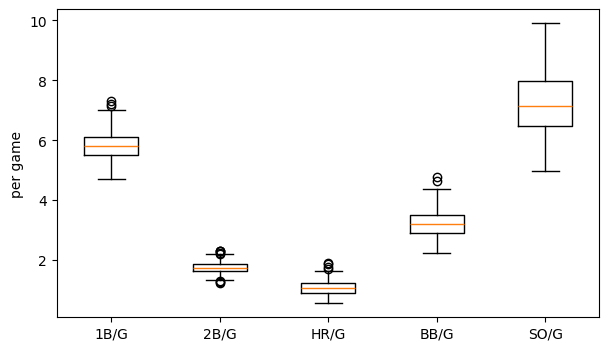

In [7]:
# boxplots of separate variables on one scale
cols = ["1B/G", "2B/G", "HR/G", "BB/G", "SO/G"]
plt.figure(figsize=(7, 4))
plt.boxplot([df[c].dropna() for c in cols], tick_labels=cols)
plt.ylabel("per game")
plt.show()

#### c)

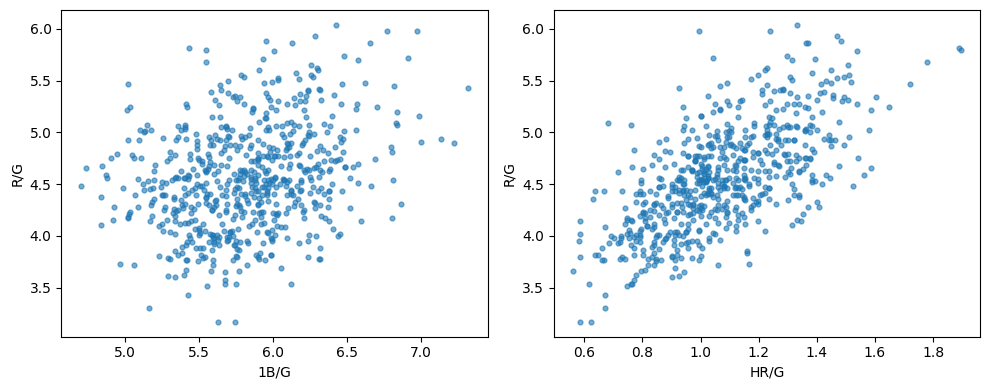

In [8]:
# simple scatters: 1B/G vs R/G, and a second pair, HR/G vs R/G
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, x in zip(axes, ["1B/G", "HR/G"]):
    ax.scatter(df[x], df["R/G"], s=12, alpha=0.6)
    ax.set_xlabel(x)
    ax.set_ylabel("R/G")
fig.tight_layout()
plt.show()